# Encoding a regulatory network in ChiRho: CRISPR knockdown effects from (synthetic) scRNA-seq

**Purpose.** A small, reviewable proof-of-concept showing *how to put prior knowledge of a gene
regulatory network* — which genes regulate which (structure) and in which direction
(polarity: activating `+`, repressing `−`, or unknown `?`) — into a
[ChiRho](https://basisresearch.github.io/chirho/) causal model, and then use ChiRho's `do()`
to ask *"what happens to every gene if we knock down gene X with CRISPR?"*

**Starting point.** The ChiRho [SciPlex tutorial](https://basisresearch.github.io/chirho/sciplex.html)
fits an independent Poisson regression per gene, with latent confounders and a drug dose as the
treatment. Genes are only linked through shared latent factors — there is no network.

**What is new here.**

| SciPlex tutorial | This notebook |
|---|---|
| Drug dose → each gene independently | CRISPR guide → one target gene → effects propagate along the network |
| No regulatory network | Prior network: edges fixed by structure, weight signs fixed by polarity |
| Several cell lines, real data | One cell type, synthetic data with known ground truth |
| Hard, single-site treatment | **Soft** knockdown (CRISPRi): target is pushed down but stays regulated |
| — | Feedback loops, handled by assuming cells are at **steady state** |

**Outline.** (2) prior network → (3) synthetic data → (4) the ChiRho model → (5–6) fitting and
checks → (7) causal queries with `do()` incl. a knockdown never seen in training →
(8) soft vs hard knockdown → (9) what goes wrong if knockdown strength is assumed →
(10) limitations.

Every section ends with a small `assert` cell: these are the notebook's tests, so
"Restart & Run All" doubles as a check that the claims in the text hold.

In [1]:
import math

import chirho
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pyro
import pyro.distributions as dist
import torch
from chirho.interventional.handlers import do
from matplotlib.lines import Line2D
from pyro.infer import Predictive

pyro.set_rng_seed(0)
torch.manual_seed(0)
rng = np.random.default_rng(0)
torch.set_default_dtype(torch.float64)
print(f"pyro {pyro.__version__}, chirho {chirho.__version__}, torch {torch.__version__}")

pyro 1.9.2, chirho 0.3.0, torch 2.13.0


## 2. The prior regulatory network

We use a toy network of six genes, `A`–`F`. The prior knowledge is a list of edges
`(regulator, target, polarity)`:

* `A → B → C ⊣ A` is a **negative feedback loop** (A activates B, B activates C, C represses A).
* `A → D ⊣ E → F` is a downstream cascade.
* `B → E` is a known interaction whose **polarity is unknown** (`?`).

CRISPR guides target `A`, `D`, `E` (used for training) and `B` (**held out** — the model never sees
cells carrying this guide; we predict them).

**Encoding.** We turn the edge list into two `G × G` matrices indexed `[target, regulator]`
(row = the gene being regulated, column = its regulator):

* `mask[g, p] = 1` if `p → g` is in the prior network, else `0` — absent edges get weight exactly 0;
* `sign[g, p] = +1` (activating), `−1` (repressing), or `0` (unknown, or no edge).

| polarity | prior on the edge weight `W[g, p]` |
|---|---|
| `+` | `HalfNormal(σ_w)` — positive only |
| `−` | `−HalfNormal(σ_w)` — negative only |
| `?` | `Normal(0, σ_w)` — either sign, learned from data |
| no edge | fixed at `0` |

In [2]:
GENES = ["A", "B", "C", "D", "E", "F"]
EDGES = [  # (regulator, target, polarity)
    ("A", "B", "+"),
    ("B", "C", "+"),
    ("C", "A", "-"),
    ("A", "D", "+"),
    ("D", "E", "-"),
    ("B", "E", "?"),
    ("E", "F", "+"),
]
TRAIN_TARGETS = ["A", "D", "E"]
HELDOUT_TARGET = "B"
GUIDE_TARGETS = [*TRAIN_TARGETS, HELDOUT_TARGET]
G, K = len(GENES), len(GUIDE_TARGETS)
IDX = {g: k for k, g in enumerate(GENES)}
TARGET_IDX = torch.tensor([IDX[t] for t in GUIDE_TARGETS])

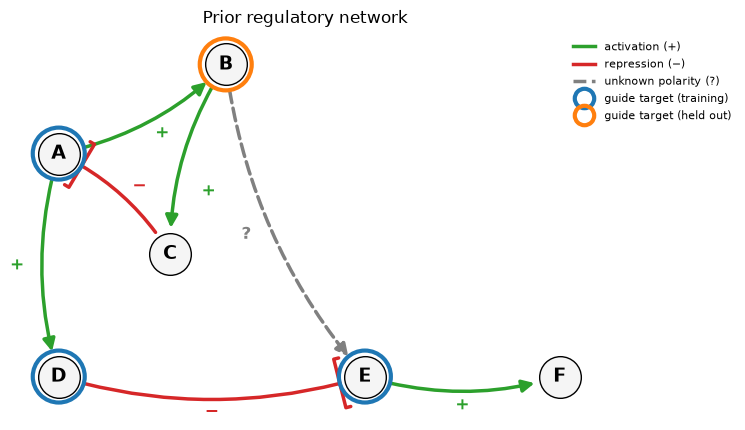

In [3]:
POLARITY = {"+": 1.0, "-": -1.0, "?": 0.0}
EDGE_STYLE = {  # polarity -> (colour, line style, arrow head)
    "+": ("tab:green", "solid", "-|>"),
    "-": ("tab:red", "solid", "-["),
    "?": ("grey", "dashed", "-|>"),
}


def prior_matrices(genes, edges):
    """Return (mask, sign), both G x G and indexed [target, regulator]."""
    idx = {g: k for k, g in enumerate(genes)}
    mask = torch.zeros(len(genes), len(genes))
    sign = torch.zeros(len(genes), len(genes))
    for parent, child, pol in edges:
        mask[idx[child], idx[parent]] = 1.0
        sign[idx[child], idx[parent]] = POLARITY[pol]
    return mask, sign


LABEL_NUDGE = {("B", "C"): (0.35, -0.35)}  # manual tweak so neighbouring labels don't collide
NODE_POS = {
    "A": (0, 0),
    "B": (1.2, 0.8),
    "C": (0.8, -0.9),
    "D": (0.0, -2.0),
    "E": (2.2, -2.0),
    "F": (3.6, -2.0),
}


def plot_network(genes, edges, targets, heldout, weights=None, ax=None, title=None):
    """Draw the signed prior network; optionally annotate edges with weights W[target, regulator]."""
    ax = ax or plt.subplots(figsize=(7.5, 5))[1]
    graph = nx.DiGraph([(p, c) for p, c, _ in edges])
    nx.draw_networkx_nodes(
        graph,
        NODE_POS,
        nodelist=genes,
        node_color="whitesmoke",
        edgecolors="black",
        node_size=900,
        ax=ax,
    )
    nx.draw_networkx_nodes(
        graph,
        NODE_POS,
        nodelist=list(targets),
        node_color="none",
        edgecolors="tab:blue",
        linewidths=3,
        node_size=1400,
        ax=ax,
    )
    nx.draw_networkx_nodes(
        graph,
        NODE_POS,
        nodelist=[heldout],
        node_color="none",
        edgecolors="tab:orange",
        linewidths=3,
        node_size=1400,
        ax=ax,
    )
    nx.draw_networkx_labels(graph, NODE_POS, font_size=14, font_weight="bold", ax=ax)
    idx = {g: k for k, g in enumerate(genes)}
    for p, c, pol in edges:
        colour, style, head = EDGE_STYLE[pol]
        nx.draw_networkx_edges(
            graph,
            NODE_POS,
            edgelist=[(p, c)],
            edge_color=colour,
            style=style,
            width=2.5,
            arrowstyle=head,
            arrowsize=18,
            node_size=1400,
            connectionstyle="arc3,rad=0.15",
            ax=ax,
        )
        symbol = {"+": "+", "-": "−", "?": "?"}[pol]
        label = symbol if weights is None else f"{symbol} ({float(weights[idx[c], idx[p]]):+.2f})"
        (x0, y0), (x1, y1) = NODE_POS[p], NODE_POS[c]
        dx, dy = x1 - x0, y1 - y0
        norm = math.hypot(dx, dy)
        # arc3 (rad=0.15) bows by ~0.075 * length along (dy, -dx); put the label just beyond the bow
        off = 0.075 * norm + 0.15
        lx, ly = (x0 + x1) / 2 + off * dy / norm, (y0 + y1) / 2 - off * dx / norm
        nx_, ny_ = LABEL_NUDGE.get((p, c), (0.0, 0.0))
        ax.text(
            lx + nx_,
            ly + ny_,
            label,
            color=colour,
            fontsize=12,
            fontweight="bold",
            ha="center",
            va="center",
        )
    legend = [
        Line2D([], [], color="tab:green", lw=2.5, label="activation (+)"),
        Line2D([], [], color="tab:red", lw=2.5, label="repression (−)"),
        Line2D([], [], color="grey", lw=2.5, ls="--", label="unknown polarity (?)"),
        Line2D(
            [],
            [],
            marker="o",
            ls="",
            mfc="none",
            mec="tab:blue",
            mew=3,
            ms=14,
            label="guide target (training)",
        ),
        Line2D(
            [],
            [],
            marker="o",
            ls="",
            mfc="none",
            mec="tab:orange",
            mew=3,
            ms=14,
            label="guide target (held out)",
        ),
    ]
    ax.legend(
        handles=legend, loc="upper right", fontsize=8, frameon=False, bbox_to_anchor=(1.25, 1.0)
    )
    ax.set_title(title or "Prior regulatory network")
    ax.axis("off")
    return ax


plot_network(GENES, EDGES, TRAIN_TARGETS, HELDOUT_TARGET)
plt.show()

In [4]:
mask, sign = prior_matrices(GENES, EDGES)
assert mask.sum() == len(EDGES)
assert mask[IDX["B"], IDX["A"]] == 1 and sign[IDX["B"], IDX["A"]] == 1
assert sign[IDX["A"], IDX["C"]] == -1
assert mask[IDX["E"], IDX["B"]] == 1 and sign[IDX["E"], IDX["B"]] == 0
assert mask[IDX["A"], IDX["B"]] == 0
print("prior network checks passed")

prior network checks passed


## 3. Ground truth and synthetic counts

**Steady-state model.** Let `z_c` be the (unobserved) log-expression of the `G` genes in cell `c`.
Each gene's log-expression is its baseline, plus the weighted sum of its regulators, plus
cell-to-cell noise, minus a knockdown shift if the cell carries a guide against it:

$$z_{cg} = b_g + \sum_p W_{gp}\, z_{cp} + e_{cg} - \sum_k \text{guide}_{ck}\, s_k\, [\text{target}(k) = g].$$

A scRNA-seq snapshot is treated as a cell that has *settled* (steady state), so this holds
simultaneously for all genes, even around the feedback loop. In matrix form
$(I - W)\, z_c = b + e_c - \text{shift}_c$, so

$$z_c = (I - W)^{-1}\,(b + e_c - \text{shift}_c).$$

This settles to a finite answer when the network's feedback is not too strong (spectral radius of
`W` below 1); we check this. **Soft knockdown:** the guide lowers the target's own equation by
`s_k`, but the target keeps all of its incoming regulation — so feedback can partly push back.

**Observation model.** We observe UMI counts $y_{cg} \sim \text{Poisson}(L_c\, e^{z_{cg}})$, where
$L_c$ is the cell's size factor (sequencing depth). Because `z` already varies between cells, the
counts are over-dispersed (a Poisson–lognormal model) and low-expressed genes produce many zeros
without needing a zero-inflation term.

**Ground truth.** We choose the edge weights (with the signs from the prior; the unknown edge
`B → E` is truly *repressive*), choose each gene's typical control log-expression `z*` and back out
baselines `b = (I − W) z*`, and choose knockdown strengths. Note `s = 1.2` means the guide alone
would cut expression to `e^{-1.2} ≈ 30 %`.

In [5]:
def steady_state(W, inputs):
    """Solve (I - W) z = inputs for z. W: [..., G, G]; inputs: [..., N, G] -> z: [..., N, G]."""
    eye = torch.eye(W.shape[-1], dtype=W.dtype)
    # cells are rows: Z (I - W)^T = inputs, solved for all N cells at once
    return torch.linalg.solve((eye - W).mT, inputs, left=False)


def knockdown_inputs(b, e, guides, s, target_idx):
    """Right-hand side b + e - shift, where each active guide k subtracts s_k from its target gene."""
    onehot = torch.nn.functional.one_hot(target_idx, b.shape[-1]).to(b.dtype)  # [K, G]
    shift = guides @ (s.unsqueeze(-1) * onehot)  # [..., N, G]
    return b + e - shift


def spectral_radius(W):
    """Largest |eigenvalue| of W (batched). < 1 means the network settles to a steady state."""
    return torch.linalg.eigvals(W).abs().max(-1).values


def true_effect(W, s_k, t):
    """Exact change in steady-state log-expression of every gene when gene t is knocked down by s_k."""
    eye = torch.eye(W.shape[-1], dtype=W.dtype)
    return -s_k * torch.linalg.inv(eye - W)[..., :, t]


mask, sign = prior_matrices(GENES, EDGES)

W_true = torch.zeros(G, G)
for (parent, child), w in {
    ("A", "B"): 0.8,
    ("B", "C"): 0.7,
    ("C", "A"): -0.6,
    ("A", "D"): 0.7,
    ("D", "E"): -0.6,
    ("B", "E"): -0.5,  # the '?' edge: truly repressive
    ("E", "F"): 0.8,
}.items():
    W_true[IDX[child], IDX[parent]] = w
z_star = torch.tensor([2.0, 1.5, 2.5, 1.0, 2.0, 3.0])  # typical control log-expression per gene
TRUE = {
    "W": W_true,
    "b": (torch.eye(G) - W_true) @ z_star,
    "s": torch.tensor([1.2, 1.6, 1.0, 1.4]),  # guides against A, D, E, B (log scale)
    "sigma_e": 0.3,
}
print(f"spectral radius of true W: {spectral_radius(TRUE['W']):.3f}")

CELLS_PER_CONDITION = 800


def simulate(conditions, n_per, seed):
    """Simulate cells for each condition (None = control, else the guide's target gene)."""
    gen = torch.Generator().manual_seed(seed)
    guides = torch.zeros(len(conditions) * n_per, K)
    for i, cond in enumerate(conditions):
        if cond is not None:
            guides[i * n_per : (i + 1) * n_per, GUIDE_TARGETS.index(cond)] = 1.0
    n = guides.shape[0]
    e = TRUE["sigma_e"] * torch.randn(n, G, generator=gen)
    z = steady_state(TRUE["W"], knockdown_inputs(TRUE["b"], e, guides, TRUE["s"], TARGET_IDX))
    size_factors = torch.exp(0.3 * torch.randn(n, generator=gen))
    counts = torch.poisson(size_factors[:, None] * torch.exp(z), generator=gen)
    return {"guides": guides, "size_factors": size_factors, "counts": counts, "z": z}


data = simulate([None, *TRAIN_TARGETS], CELLS_PER_CONDITION, seed=1)
heldout_data = simulate([HELDOUT_TARGET], CELLS_PER_CONDITION, seed=2)
CONDITION = np.array(
    ["control"] * CELLS_PER_CONDITION
    + [f"KD {t}" for t in TRAIN_TARGETS for _ in range(CELLS_PER_CONDITION)]
)
print(
    f"training cells: {data['counts'].shape[0]}, held-out cells (guide {HELDOUT_TARGET}): {heldout_data['counts'].shape[0]}"
)

spectral radius of true W: 0.695
training cells: 3200, held-out cells (guide B): 800


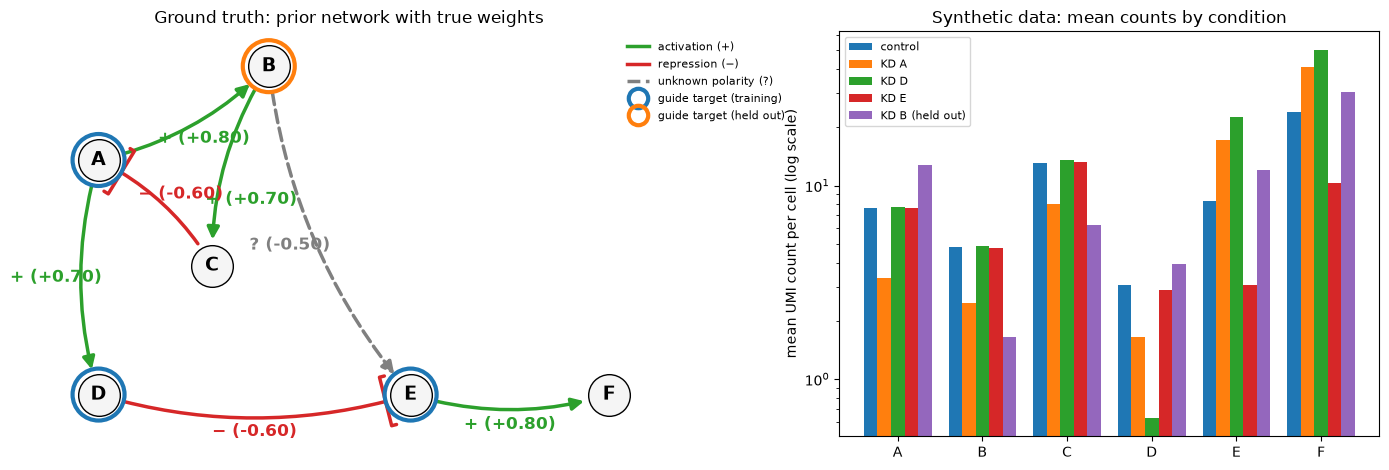

fraction of zero counts: 0.06


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
plot_network(
    GENES,
    EDGES,
    TRAIN_TARGETS,
    HELDOUT_TARGET,
    weights=TRUE["W"],
    ax=axes[0],
    title="Ground truth: prior network with true weights",
)
mean_counts = {
    c: data["counts"][CONDITION == c].mean(0)
    for c in ["control", *[f"KD {t}" for t in TRAIN_TARGETS]]
}
mean_counts[f"KD {HELDOUT_TARGET} (held out)"] = heldout_data["counts"].mean(0)
width = 0.16
for j, (cond, m) in enumerate(mean_counts.items()):
    axes[1].bar(np.arange(G) + (j - 2) * width, m.numpy(), width, label=cond)
axes[1].set_xticks(range(G), GENES)
axes[1].set_yscale("log")
axes[1].set_ylabel("mean UMI count per cell (log scale)")
axes[1].set_title("Synthetic data: mean counts by condition")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"fraction of zero counts: {(data['counts'] == 0).double().mean():.2f}")

In [7]:
assert spectral_radius(TRUE["W"]) < 1
# the solver agrees with simply iterating the equations until they settle
x = torch.randn(5, G)
z_iter = torch.zeros_like(x)
for _ in range(500):
    z_iter = x + z_iter @ TRUE["W"].T
assert torch.allclose(steady_state(TRUE["W"], x), z_iter, atol=1e-6)
# every cell carries at most one guide, and nobody in training carries the held-out guide
assert (data["guides"].sum(-1) <= 1).all()
assert (data["guides"][:, GUIDE_TARGETS.index(HELDOUT_TARGET)] == 0).all()
assert ((TRUE["W"] != 0).double() == mask).all()
assert torch.all(TRUE["W"][sign == 1] > 0) and torch.all(TRUE["W"][sign == -1] < 0)
# each training knockdown visibly lowers its own target, close to the analytic effect
logexpr = torch.log((data["counts"] + 0.5) / data["size_factors"][:, None])
ctrl = data["guides"].sum(-1) == 0
for t in TRAIN_TARGETS:
    k = GUIDE_TARGETS.index(t)
    kd = data["guides"][:, k] == 1
    shift = logexpr[kd, IDX[t]].mean() - logexpr[ctrl, IDX[t]].mean()
    expected = true_effect(TRUE["W"], TRUE["s"][k], IDX[t])[IDX[t]]
    assert shift < 0 and expected < 0, (t, shift, expected)
print("simulation checks passed")

simulation checks passed


## 4. The ChiRho model: where the network goes

The model is an ordinary Pyro program; ChiRho adds the causal operations (`do`, counterfactual
worlds) on top. The regulatory network enters in exactly two places:

1. **Structure → which weights exist.** Only edges in the prior network get a weight; every other
   entry of `W` is a hard zero (via `mask`).
2. **Polarity → the sign of each weight.** Activating edges are sampled from a positive
   distribution, repressing edges from a negative one, unknown edges from a symmetric one.

The CRISPR knockdown enters as **guide variables** `guide_A`, `guide_D`, … — one observed 0/1 sample
site per guide per cell. Because they are sample sites, ChiRho can intervene on them:
`do(actions={"guide_B": 1.0})` means *"give every cell a guide against B"*. The knockdown shift is
applied *inside* the gene's equation before the steady-state solve, so its effect travels through
the whole network — including around the feedback loop and back onto the target itself.

> Why not `do()` directly on a gene? ChiRho does support soft interventions on a value
> (e.g. `do(actions={"x": lambda x: x - 1.5})`), but shifting a gene's value *after* the joint
> steady-state solve would not propagate to the genes it regulates. Intervening on the guide —
> which is what the experimenter actually controls — gives the right semantics.

Knockdown strengths `s_k` are learned, one per guide, from a **shared population** of guide
strengths (`μ_s`, `τ_s`). A guide with no training cells (here, the one against `B`) therefore
gets its strength from that population — which is how we can predict a knockdown never observed.

`hard=True` switches to a hard knockdown at query time: the target's incoming edges are cut, so
its regulators (and the feedback loop) no longer act on it. `fixed_strength` replaces the learned
strengths with a constant, used in Section 9.

In [8]:
SIGMA_W = 1.0
POS_EDGES = torch.nonzero((mask == 1) & (sign == 1), as_tuple=True)
NEG_EDGES = torch.nonzero((mask == 1) & (sign == -1), as_tuple=True)
UNK_EDGES = torch.nonzero((mask == 1) & (sign == 0), as_tuple=True)
TARGET_ONEHOT = torch.nn.functional.one_hot(TARGET_IDX, G).double()  # [K, G]


def grn_model(guides, size_factors, counts=None, hard=False, fixed_strength=None):
    """Steady-state, network-structured model of CRISPR scRNA-seq counts.

    guides: [N, K] 0/1 guide assignment; size_factors: [N]; counts: [N, G] or None.
    """
    n_cells = guides.shape[0]

    # --- prior network: structure (mask) + polarity (sign-constrained priors) ---
    w_pos = pyro.sample("w_pos", dist.HalfNormal(SIGMA_W).expand([len(POS_EDGES[0])]).to_event(1))
    w_neg = pyro.sample("w_neg", dist.HalfNormal(SIGMA_W).expand([len(NEG_EDGES[0])]).to_event(1))
    w_unk = pyro.sample("w_unk", dist.Normal(0.0, SIGMA_W).expand([len(UNK_EDGES[0])]).to_event(1))
    W = torch.zeros(G, G)
    W = W.index_put(POS_EDGES, w_pos).index_put(NEG_EDGES, -w_neg).index_put(UNK_EDGES, w_unk)
    W = pyro.deterministic("W", W, event_dim=2)  # absent edges stay exactly 0

    # --- gene baselines and cell-to-cell noise scale ---
    b = pyro.sample("b", dist.Normal(1.0, 2.0).expand([G]).to_event(1))
    sigma_e = pyro.sample("sigma_e", dist.HalfNormal(0.5))

    # --- knockdown strength per guide, from a shared population of guides ---
    mu_s = pyro.sample("mu_s", dist.Normal(math.log(1.2), 0.5))
    tau_s = pyro.sample("tau_s", dist.HalfNormal(0.3))
    if fixed_strength is None:
        s = pyro.sample("s", dist.LogNormal(mu_s, tau_s).expand([K]).to_event(1))
    else:
        s = pyro.deterministic("s", torch.full((K,), float(fixed_strength)), event_dim=1)

    with pyro.plate("cells", n_cells, dim=-1):
        # guide sites: observed here, intervened on with do() later
        guide_vals = [
            pyro.sample(f"guide_{t}", dist.Bernoulli(0.25), obs=guides[:, k])
            for k, t in enumerate(GUIDE_TARGETS)
        ]
        guide_mat = torch.stack(torch.broadcast_tensors(*guide_vals), dim=-1)  # [..., N, K]

        e = pyro.sample("e", dist.Normal(0.0, sigma_e).expand([G]).to_event(1))
        inputs = knockdown_inputs(b, e, guide_mat, s, TARGET_IDX)  # b + e - knockdown shift
        if hard:
            # hard knockdown: cut every incoming edge of a knocked-down gene, per cell
            knocked = (guide_mat @ TARGET_ONEHOT).clamp(max=1.0)  # [..., N, G]
            W_cell = W * (1.0 - knocked.unsqueeze(-1))  # zero the target's row
            eye = torch.eye(G)
            z = torch.linalg.solve(eye - W_cell, inputs.unsqueeze(-1)).squeeze(-1)
        else:
            z = steady_state(W, inputs)
        z = pyro.deterministic("z", z, event_dim=1)
        pyro.sample(
            "counts",
            dist.Poisson(size_factors.unsqueeze(-1) * torch.exp(z)).to_event(1),
            obs=counts,
        )
    return z

### The probabilistic model as a graph

Rendered directly from the code with `pyro.render_model`. Solid grey nodes are observed (guides, counts); dashed
nodes are deterministic functions of their parents (`W`, `z`); the box is the plate over cells. Read top to bottom: the edge weights (`w_pos`, `w_neg`, `w_unk`) assemble into the
network matrix `W`; together with baselines `b`, per-cell noise `e`, the guides and their
strengths `s`, they determine the steady state `z`, which generates the observed `counts`.

| node | meaning |
|---|---|
| `w_pos`, `w_neg`, `w_unk` | weights of activating / repressing / unknown-polarity edges |
| `W` | network matrix (deterministic; zero where the prior has no edge) |
| `b` | baseline log-expression per gene |
| `sigma_e`, `e` | scale and value of cell-to-cell variability |
| `mu_s`, `tau_s` | typical guide strength and guide-to-guide spread |
| `s` | knockdown strength of each guide (log scale) |
| `guide_A`, `guide_D`, `guide_E`, `guide_B` | which guide a cell carries — the intervention handles |
| `z` | steady-state log-expression (deterministic) |
| `counts` | observed UMI counts |

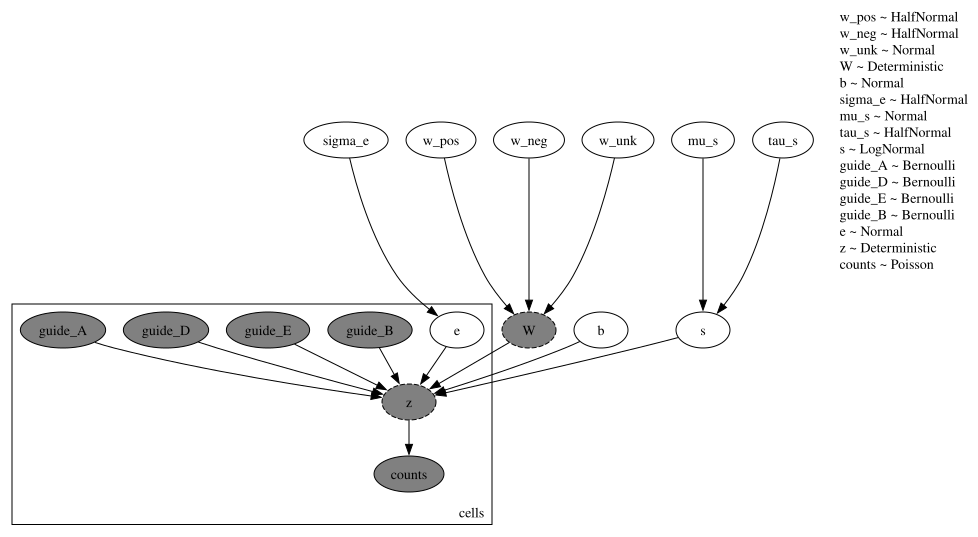

In [9]:
pyro.render_model(
    grn_model,
    model_args=(data["guides"][:20], data["size_factors"][:20], data["counts"][:20]),
    render_distributions=True,
    render_deterministic=True,
)

In [10]:
n_chk = 10
args_chk = (data["guides"][:n_chk], data["size_factors"][:n_chk])
Wp = Predictive(grn_model, num_samples=200, return_sites=["W"])(*args_chk)["W"].reshape(-1, G, G)
assert (Wp[:, mask == 0] == 0).all()  # structure: absent edges are exactly zero
assert (Wp[:, sign == 1] > 0).all() and (Wp[:, sign == -1] < 0).all()  # polarity respected
unknown = (mask == 1) & (sign == 0)
assert (Wp[:, unknown] > 0).any() and (
    Wp[:, unknown] < 0
).any()  # unknown edge can take either sign

# do() on a guide lowers its target, with all other randomness held fixed
no_guides = torch.zeros(n_chk, K)
with pyro.poutine.seed(rng_seed=1):
    z0 = do(grn_model, {"guide_A": torch.zeros(n_chk)})(no_guides, args_chk[1])
with pyro.poutine.seed(rng_seed=1):
    z1 = do(grn_model, {"guide_A": torch.ones(n_chk)})(no_guides, args_chk[1])
assert (z1[:, IDX["A"]] < z0[:, IDX["A"]]).all()
# hard and soft agree when no guide is active
with pyro.poutine.seed(rng_seed=1):
    z0_hard = grn_model(no_guides, args_chk[1], hard=True)
assert torch.allclose(z0, z0_hard)
print("model checks passed")

model checks passed
